# Week 11: Multi-Class Classification and Evaluation

This notebook focuses on how to **evaluate and understand a multi-class classification model**, not just how to train one.

We will use the MNIST handwritten-digit dataset and begin with a simple neural-network classifier. From there, the emphasis shifts to a more important practical question:

> **Once a model is working, how do we understand what it gets right, what it gets wrong, and whether its summary metrics are telling the whole story?**

The notebook develops that idea in several stages.

We first use the **confusion matrix** to examine class-by-class behavior and identify common error patterns. We then drill down from global error summaries to individual examples and their **softmax probability distributions**, showing how two predictions that look identical in a confusion matrix can reflect very different levels of model confidence.

Next, we examine **multi-class evaluation metrics**, including per-class precision, recall, and F1, along with macro, weighted, and micro averages. This allows us to see how different summaries answer different questions about model performance.

Finally, we deliberately introduce **class imbalance** into the training data. This provides a controlled example of how a model can maintain strong overall accuracy while performing poorly on a minority class, and it gives us a practical setting in which to examine class weighting and metric tradeoffs.

The main themes of the notebook are:

- a single accuracy score is rarely enough;
- different metrics reveal different aspects of model behavior;
- error analysis should move from global summaries to specific examples;
- class imbalance can hide important weaknesses;
- model evaluation should guide what we investigate or change next.

The goal is not simply to produce a high-performing classifier, but to develop a systematic way to **diagnose, interpret, and improve classification models**.

## 1. Setup and Data Loading
Import necessary libraries and preprocess the MNIST dataset.

In [1]:
# Imports and global variables

import math
import numpy as np
import os
import time
import matplotlib.pyplot as plt
import pandas as pd

from tqdm.notebook import tqdm
from collections import Counter

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

import tensorflow as tf

tf.config.experimental.enable_op_determinism()

# Disable GPU / Apple Metal
tf.config.set_visible_devices([], "GPU")

print("Visible devices:", tf.config.get_visible_devices())

from tensorflow import keras
from tensorflow.keras import models, layers, regularizers, callbacks
from tensorflow.keras.callbacks import Callback,EarlyStopping,ReduceLROnPlateau,LearningRateScheduler
from tensorflow.keras.layers import Input, Dense, ReLU, BatchNormalization, Dropout, LeakyReLU
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.optimizers.schedules import ExponentialDecay, CosineDecay, PiecewiseConstantDecay

# utility code

def format_hms(seconds):
    return time.strftime("%H:%M:%S", time.gmtime(seconds))

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # Suppresses INFO and WARNING messages

Visible devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [2]:
# Utility to record results by title of experiment

results = {}

def print_results():

    print(f"{'Model':<40} {'Val Acc':>10} {'Val Loss':>10} {'Best Epoch':>12} {'Epochs Run':>12}")
    print("-" * 90)

    for title, r in sorted(
        results.items(),
        key=lambda kv: kv[1]["val_accuracy"],
        reverse=True
    ):
        print(
            f"{title:<40} "
            f"{r['val_accuracy']:>10.4f} "
            f"{r['val_loss']:>10.4f} "
            f"{r['best_epoch']:>12} "
            f"{r['epochs_run']:>12}"
        )

In [3]:
# Utility to print learning curves

def plot_learning_curves(hist, 
                         title="Learning Curves", 
                         best_epoch=None,              # None = print absolute minimum val_loss point on both plots
                                                       # else assume is 0-based early stopping trigger point
                         verbose=True
                        ):

    val_losses = hist.history['val_loss']
    
    if best_epoch is not None:
        min_val_epoch = best_epoch
    else:
        min_val_epoch = val_losses.index(min(val_losses))
        
    val_loss_at_min_loss = hist.history['val_loss'][min_val_epoch]    
    val_acc_at_min_loss = hist.history['val_accuracy'][min_val_epoch]
    

    n_epochs = len(val_losses)
    epochs = list(range(1, n_epochs + 1))

    # Determine tick interval and xticks starting from 0

    tick_interval = max(1, n_epochs // 20)
    xticks = list(range(0, n_epochs + 1, tick_interval))

    plt.figure(figsize=(8, 8))

    # --- Loss Plot ---
    plt.subplot(2, 1, 1)
    plt.plot(epochs, hist.history['loss'], label='Train Loss')
    plt.plot(epochs, hist.history['val_loss'], label='Val Loss')
    plt.scatter(min_val_epoch + 1, val_loss_at_min_loss, color='red', marker='x', s=50, label='Min Val Loss') 
    plt.title(f'{title} - Loss')
    plt.ylabel('Loss')
    plt.xticks(xticks)
    plt.legend()
    plt.grid(True)

    # --- Accuracy Plot ---
    plt.subplot(2, 1, 2)
    plt.plot(epochs, hist.history['accuracy'], label='Train Accuracy')
    plt.plot(epochs, hist.history['val_accuracy'], label='Val Accuracy')
    plt.scatter(min_val_epoch + 1, val_acc_at_min_loss, color='red', marker='x', s=50, label='Acc @ Min Val Loss')
    plt.title(f'{title} - Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    # plt.ylim(0, 1.05)
    plt.xticks(xticks)
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

    if verbose:
        print(f"Final Training Loss:            {hist.history['loss'][-1]:.4f}")
        print(f"Final Training Accuracy:        {hist.history['accuracy'][-1]:.4f}")
        print(f"Final Validation Loss:          {hist.history['val_loss'][-1]:.4f}")
        print(f"Final Validation Accuracy:      {hist.history['val_accuracy'][-1]:.4f}")
        print(f"Minimum Validation Loss:        {val_loss_at_min_loss:.4f} (Epoch {min_val_epoch + 1})")
        print(f"Validation Accuracy @ Min Loss: {val_acc_at_min_loss:.4f}")


In [4]:
# Globals and train_and_validate

epochs = 100
batch_size = 128
learning_rate = 1e-3     # Adam default

# Assumes X_train, y_train, X_val, y_val defined as globals before call

def train_and_validate(
    model,
    epochs=epochs,
    learning_rate=learning_rate,
    optimizer="Adam",
    title="Learning Curves",
    batch_size=batch_size,
    use_early_stopping=True,
    patience=6,
    min_delta=0.0001,
    extra_callbacks=None,
    class_weight=None,          # NEW
    verbose=0,
    return_history=False
):

    if extra_callbacks is None:
        extra_callbacks = []

    print(f"\n{title}")

    # --------------------------------------------------
    # Optimizer
    # --------------------------------------------------

    if optimizer == "Adam":
        opt = Adam(learning_rate=learning_rate)
    else:
        opt = optimizer

    # Compile here, in one place.
    model.compile(
        optimizer=opt,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    # --------------------------------------------------
    # Callbacks
    # --------------------------------------------------

    callbacks_list = list(extra_callbacks)

    early_stop = None

    if use_early_stopping:

        early_stop = EarlyStopping(
            monitor="val_loss",
            patience=patience,
            min_delta=min_delta,
            restore_best_weights=True,
            verbose=verbose
        )

        callbacks_list.insert(0, early_stop)

    # --------------------------------------------------
    # Train
    #
    # IMPORTANT:
    # X_val and y_val are a fixed validation set created
    # once before these experiments begin.
    #
    # The test set is NOT used here.
    # --------------------------------------------------

    start = time.time()

    history = model.fit(
        X_train,
        y_train,
        epochs=epochs,
        batch_size=batch_size,
        validation_data=(X_val, y_val),
        callbacks=callbacks_list,
        class_weight=class_weight,
        verbose=verbose
    )

    end = time.time()

    # --------------------------------------------------
    # Identify best validation epoch
    # --------------------------------------------------

    val_losses = history.history["val_loss"]

    if use_early_stopping:
        # This is the epoch whose weights Keras restored.
        best_epoch = early_stop.best_epoch
    else:
        # For reporting only. Without early stopping,
        # the model itself still has the final epoch's weights.
        best_epoch = int(np.argmin(val_losses))

    best_val_loss = history.history["val_loss"][best_epoch]
    best_val_acc  = history.history["val_accuracy"][best_epoch]

    epochs_run = len(history.history["loss"])

    # --------------------------------------------------
    # Plot learning curves
    # --------------------------------------------------

    plot_learning_curves(
        history,
        title=title,
        best_epoch=best_epoch
    )

    # --------------------------------------------------
    # Summary
    # --------------------------------------------------

    print(f"\nEpochs trained:                 {epochs_run}")
    print(f"Best validation epoch:          {best_epoch + 1}")
    print(f"Best validation loss:           {best_val_loss:.4f}")
    print(f"Validation accuracy at best:    {best_val_acc:.4f}")

    if use_early_stopping:
        print(
            f"Model weights restored from:    "
            f"epoch {best_epoch + 1}"
        )
    else:
        print(
            f"Model weights retained from:    "
            f"final epoch {epochs_run}"
        )

    print(f"Execution time:                 {format_hms(end - start)}")

    # Save results for later comparison.
    results[title] = {
        "val_loss": best_val_loss,
        "val_accuracy": best_val_acc,
        "best_epoch": best_epoch + 1,
        "epochs_run": epochs_run
    }

    if return_history:
        return history

In [5]:
# Load MNIST
(X_development, y_development), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

# Flatten and rescale images
X_development = X_development.reshape(-1, 784).astype("float32") / 255.0
X_test        = X_test.reshape(-1, 784).astype("float32") / 255.0

num_classes = 10

# Split the development set into fixed training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_development,
    y_development,
    test_size=0.20,
    random_state=42,
    stratify=y_development
)

print("Development set:", X_development.shape, y_development.shape)
print("Training set:   ", X_train.shape, y_train.shape)
print("Validation set: ", X_val.shape, y_val.shape)
print("Test set:       ", X_test.shape, y_test.shape)

Development set: (60000, 784) (60000,)
Training set:    (48000, 784) (48000,)
Validation set:  (12000, 784) (12000,)
Test set:        (10000, 784) (10000,)


## 2. Baseline Multi-Class Model and Error Analysis

### A. Baseline Model 
We'll define a simple model and plot learning curves (training vs validation loss & accuracy).



Baseline Model


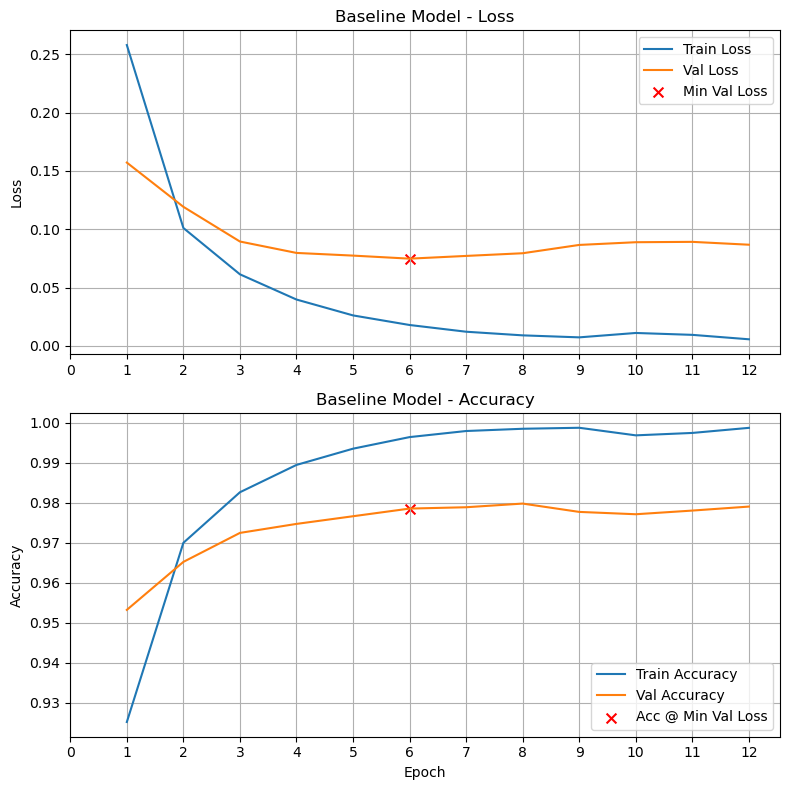

Final Training Loss:            0.0056
Final Training Accuracy:        0.9988
Final Validation Loss:          0.0867
Final Validation Accuracy:      0.9791
Minimum Validation Loss:        0.0748 (Epoch 6)
Validation Accuracy @ Min Loss: 0.9786

Epochs trained:                 12
Best validation epoch:          6
Best validation loss:           0.0748
Validation accuracy at best:    0.9786
Model weights restored from:    epoch 6
Execution time:                 00:00:19


In [6]:
tf.keras.utils.set_random_seed(42)

baseline_width = 1024

baseline_model = models.Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(
        baseline_width,
        activation="relu",
        kernel_initializer="he_uniform"
    ),
    Dense(
        num_classes,
        activation="softmax"
    )
])

# display(baseline_model.summary())

train_and_validate(
    baseline_model,
    title="Baseline Model",
    use_early_stopping=True,
    verbose=0
)

## B. Four Views of the Confusion Matrix

A confusion matrix summarizes where the model is correct and where it confuses one class with another. The raw counts contain all of the underlying information, but counts alone can be difficult to interpret.

By changing the denominator, we can express the same confusion matrix in different ways. **The predictions do not change; only the perspective changes.** Each view answers a different question about the model's performance.

We will examine four views:

- **Raw counts:** *How many examples fall in each actual–predicted combination?*  
  This shows the number of correct predictions and mistakes directly.

- **Percent of all examples:** *How much of the entire validation set does each cell represent?*  
  Each cell is divided by the total number of validation examples, showing its contribution to overall performance.

- **Row normalized:** *Given the actual class, what did the model predict?*  
  Each row sums to 100%. This shows how well the model recognizes each class, so the diagonal entries correspond to **recall** for each class.

- **Errors only:** *Of all the mistakes the model made, where are those errors concentrated?*  
  We first set the diagonal to zero, removing the correct predictions. Each remaining cell is then divided by the total number of misclassified examples. This makes it easier to see which specific confusion pairs account for the largest share of the model's errors.

Together, these views move from a general summary of performance toward a more focused analysis of the model's mistakes. The final view will be especially useful for deciding which confusion pairs to investigate in more detail.

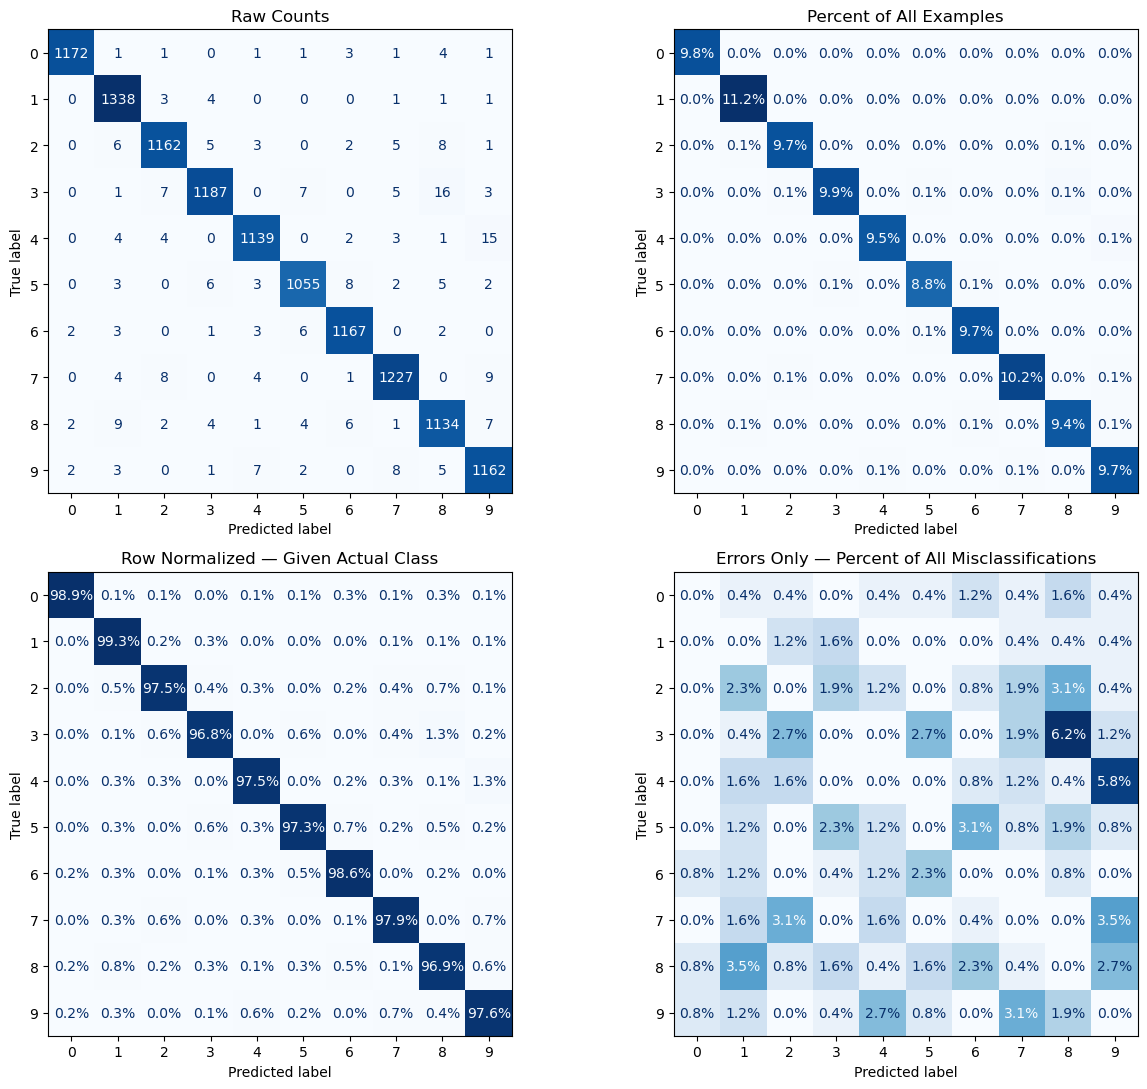

In [7]:
# Predict probabilities for the validation set
y_val_prob = baseline_model.predict(
    X_val,
    verbose=0
)

# Predicted class = class with highest probability
y_val_pred = np.argmax(
    y_val_prob,
    axis=1
)

# Original confusion matrix: raw counts
cm = confusion_matrix(
    y_val,
    y_val_pred
)


# --------------------------------------------------
# Create the four confusion-matrix views
# --------------------------------------------------

# 1. Raw counts
cm_count = cm.copy()

# 2. Percent of all validation examples
cm_all = (
    cm / cm.sum()
)

# 3. Row normalized:
#    Given the actual class, what did the model predict?
cm_row = (
    cm / cm.sum(axis=1, keepdims=True)
)

# 4. Errors only:
#    Of all misclassified examples, where did the errors occur?
cm_error = cm.astype(float).copy()

# Remove correct predictions
np.fill_diagonal(
    cm_error,
    0
)

# Normalize by ALL misclassified examples
cm_error = (
    cm_error / cm_error.sum()
)


# --------------------------------------------------
# Plot the four views
# --------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 11)
)

matrices = [
    (
        cm_count,
        "Raw Counts",
        "d"
    ),
    (
        cm_all,
        "Percent of All Examples",
        ".1%"
    ),
    (
        cm_row,
        "Row Normalized — Given Actual Class",
        ".1%"
    ),
    (
        cm_error,
        "Errors Only — Percent of All Misclassifications",
        ".1%"
    )
]


for ax, (matrix, title, fmt) in zip(
    axes.ravel(),
    matrices
):

    disp = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=range(num_classes)
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format=fmt,
        colorbar=False
    )

    ax.set_title(title)


plt.tight_layout()
plt.show()

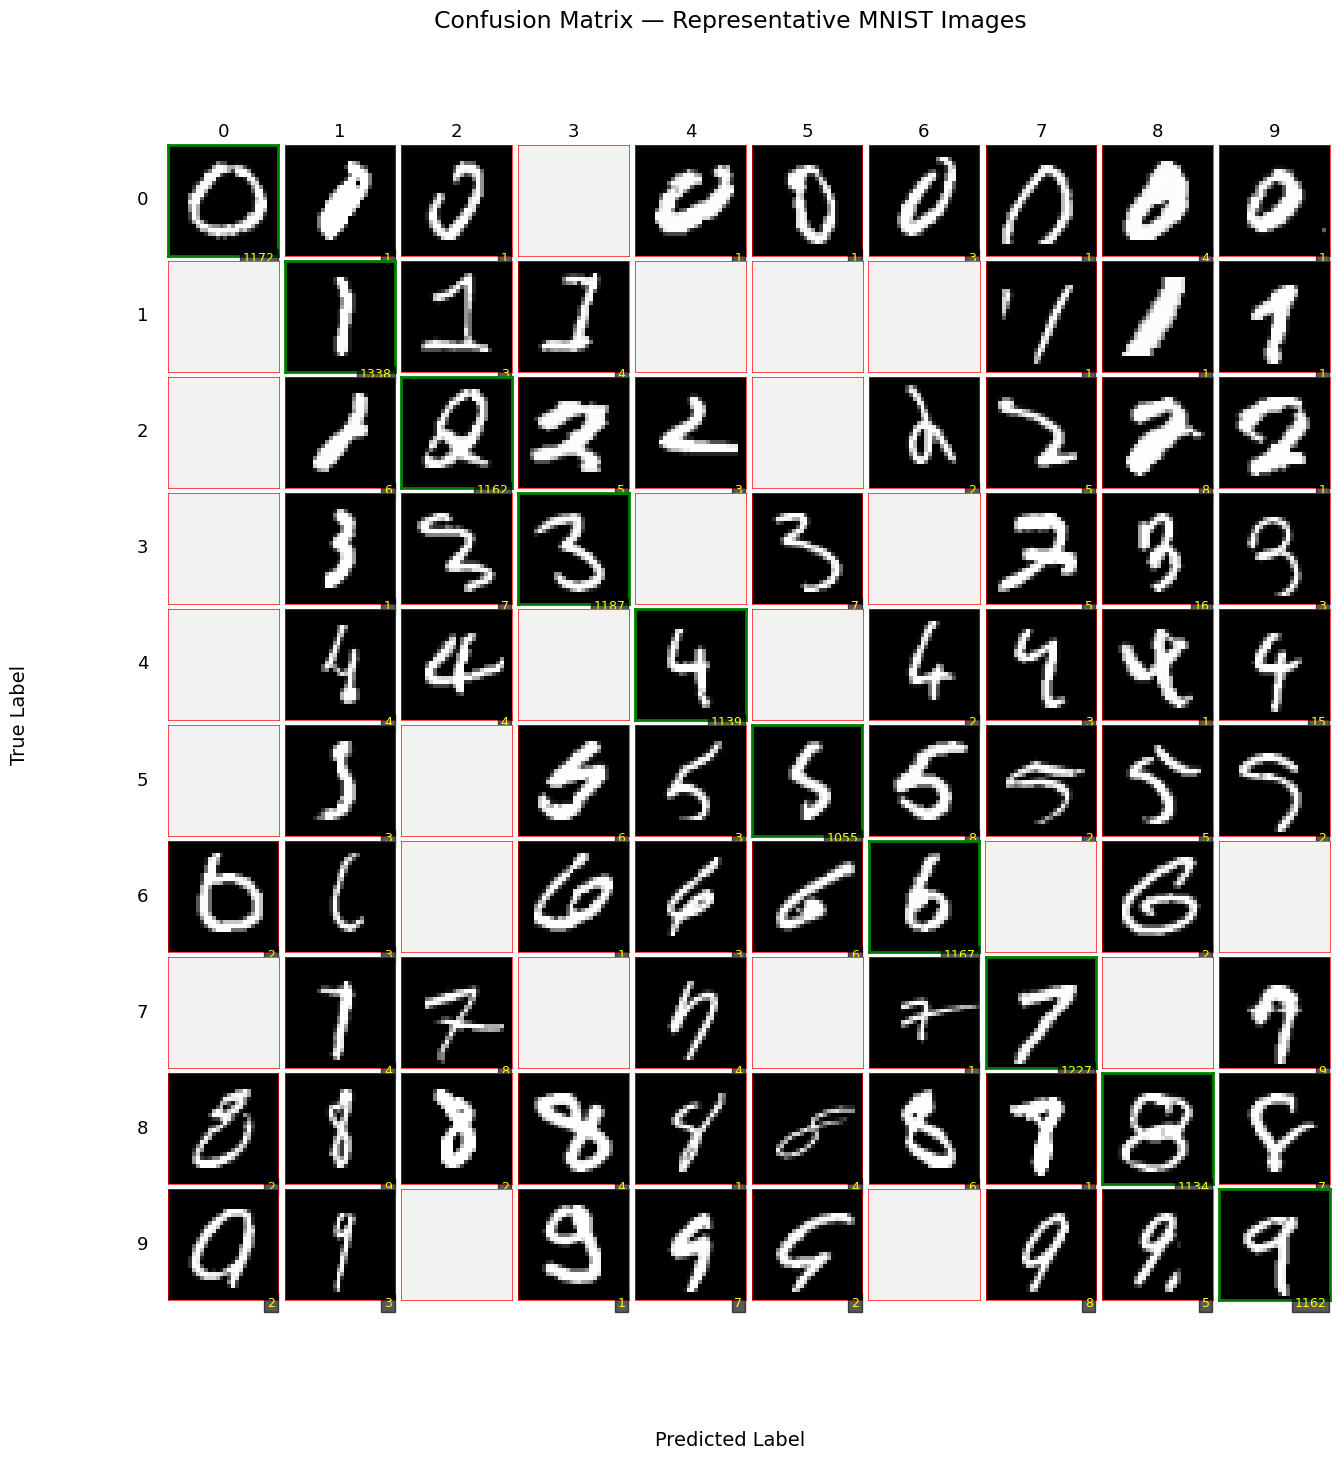

In [8]:
# --------------------------------------------------
# Confusion matrix with representative MNIST images
# --------------------------------------------------

rng = np.random.default_rng(42)

fig, axes = plt.subplots(
    num_classes,
    num_classes,
    figsize=(15, 15)
)

for actual in range(num_classes):
    for predicted in range(num_classes):

        ax = axes[actual, predicted]

        # Find validation examples belonging to this cell
        indices = np.where(
            (y_val == actual) &
            (y_val_pred == predicted)
        )[0]

        ax.set_xticks([])
        ax.set_yticks([])

        if len(indices) > 0:

            # Select one representative example
            idx = rng.choice(indices)

            # Display the actual handwritten digit
            image = X_val[idx].reshape(28, 28)

            ax.imshow(
                image,
                cmap="gray",
                vmin=0,
                vmax=1
            )

            # Display count in upper-right corner
            ax.text(
                0.97, 0.03,
                str(cm[actual, predicted]),
                transform=ax.transAxes,
                ha="right",
                va="top",
                fontsize=9,
                color="yellow",
                bbox=dict(
                    facecolor="black",
                    alpha=0.65,
                    pad=2
                )
            )

        else:
            ax.set_facecolor("#f2f2f2")

        # Highlight correct classifications
        border_color = (
            "green" if actual == predicted else "red"
        )

        for spine in ax.spines.values():
            spine.set_edgecolor(border_color)
            spine.set_linewidth(
                2 if actual == predicted else 0.5
            )

# Column labels
for j in range(num_classes):
    axes[0, j].set_title(
        str(j),
        fontsize=13
    )

# Row labels
for i in range(num_classes):
    axes[i, 0].set_ylabel(
        str(i),
        fontsize=13,
        rotation=0,
        labelpad=18,
        va="center"
    )

fig.suptitle(
    "Confusion Matrix — Representative MNIST Images",
    fontsize=17,
    y=0.97
)

fig.supxlabel("Predicted Label", fontsize=14)
fig.supylabel("True Label", fontsize=14)

plt.subplots_adjust(
    wspace=0.05,
    hspace=0.05
)

plt.show()

### C. Identify Easiest and Hardest Classes

> Here, “hardest” means the class with the lowest recall—the class the model is most likely to miss. “Easiest” means the class with the highest recall.

The diagonal of the **row-normalized confusion matrix** gives the **recall** for each class:

> **Of all examples that actually belong to this class, what fraction did the model classify correctly?**

A lower diagonal value means the model misses that class more often, while a higher value means the class is recognized more reliably.

We can therefore rank the classes by their diagonal values:

In [9]:
class_recall = np.diag(cm_row)

order = np.argsort(class_recall)

print("Hardest to easiest:\n")

for c in order:
    print(f"Class {c}: {class_recall[c]:.3f}")


Hardest to easiest:

Class 3: 0.968
Class 8: 0.969
Class 5: 0.973
Class 2: 0.975
Class 4: 0.975
Class 9: 0.976
Class 7: 0.979
Class 6: 0.986
Class 0: 0.989
Class 1: 0.993


### D. Find the Most Important Confusion Pairs

The error-only confusion matrix tells us **where the model's mistakes are concentrated**.

Because the diagonal has been removed and the remaining cells are expressed as a percentage of **all misclassified examples**, we can rank the off-diagonal cells directly.

Each entry now answers:

> **Of all the errors made by the model, what fraction were this particular actual → predicted confusion?**

This gives us a practical way to prioritize our error analysis. Rather than inspecting mistakes at random, we can begin with the confusion pairs that account for the largest share of the model's total errors.

We will now rank those confusion pairs from most common to least common.

In [10]:
cm_errors = cm_error.copy()

np.fill_diagonal(cm_errors, 0)

confusions = []

for actual in range(num_classes):
    for predicted in range(num_classes):

        if actual != predicted:

            confusions.append(
                (
                    cm_errors[actual, predicted],
                    actual,
                    predicted
                )
            )

confusions.sort(reverse=True)

print("Largest confusion rates:\n")

for rate, actual, predicted in confusions[:10]:

    print(
        f"Actual {actual} → Predicted {predicted}: "
        f"{rate:.1%}"
    )

Largest confusion rates:

Actual 3 → Predicted 8: 6.2%
Actual 4 → Predicted 9: 5.8%
Actual 8 → Predicted 1: 3.5%
Actual 7 → Predicted 9: 3.5%
Actual 9 → Predicted 7: 3.1%
Actual 7 → Predicted 2: 3.1%
Actual 5 → Predicted 6: 3.1%
Actual 2 → Predicted 8: 3.1%
Actual 9 → Predicted 4: 2.7%
Actual 8 → Predicted 9: 2.7%


### E. Pick One Confusion and Inspect the Examples

A confusion matrix tells us **which classes are being confused**, but not **why** the model is making those mistakes.

To investigate further, we will choose one common confusion pair and look at the individual validation examples that produced it.

For each example, we will examine both:

- the handwritten digit itself, and
- the model's softmax probability distribution.

This lets us distinguish between different kinds of errors. Some may be **close calls**, where the correct and predicted classes receive similar probabilities. Others may be **confident errors**, where the model strongly prefers the wrong class.

Rather than inspect every example in the pair, we will **select a few that span this range from uncertain to confident mistakes.**

In [11]:
# Show softmax probabilities for one validation example

def show_prediction(i):

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    # Left: softmax probabilities
    axes[0].bar(
        range(num_classes),
        y_val_prob[i]
    )

    axes[0].set_xticks(range(num_classes))
    axes[0].set_xlabel("Class")
    axes[0].set_ylabel("Probability")
    axes[0].set_ylim(0, 1)

    axes[0].grid(axis="y")
    axes[0].set_axisbelow(True)

    axes[0].set_title(
        f"Actual: {y_val[i]}   Predicted: {y_val_pred[i]}"
    )

    # Right: image
    axes[1].imshow(
        X_val[i].reshape(28, 28),
        cmap="gray"
    )

    axes[1].set_title(f"Actual Digit: {y_val[i]}")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    print()
    print()
    
# for i in [3,2,9,48]:
#     show_prediction(i)



Largest confusion: 3 → 8 (0.062)
16 examples total

Showing three examples from close to confidently wrong:

Predicted probability = 0.500, actual-class probability = 0.496, margin = 0.003



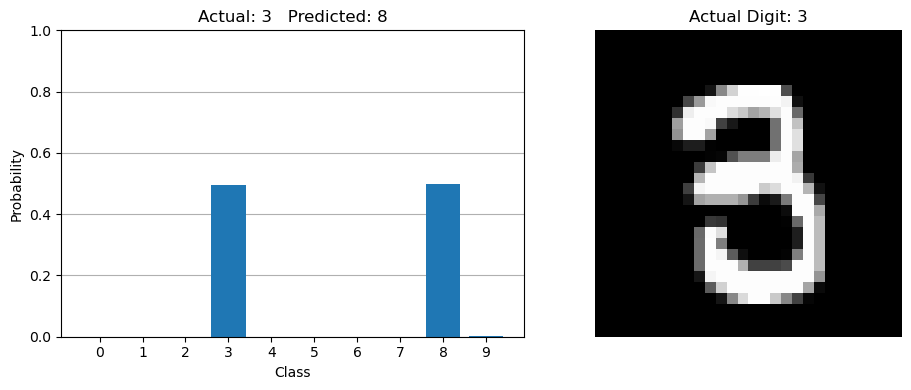



Predicted probability = 0.760, actual-class probability = 0.071, margin = 0.689



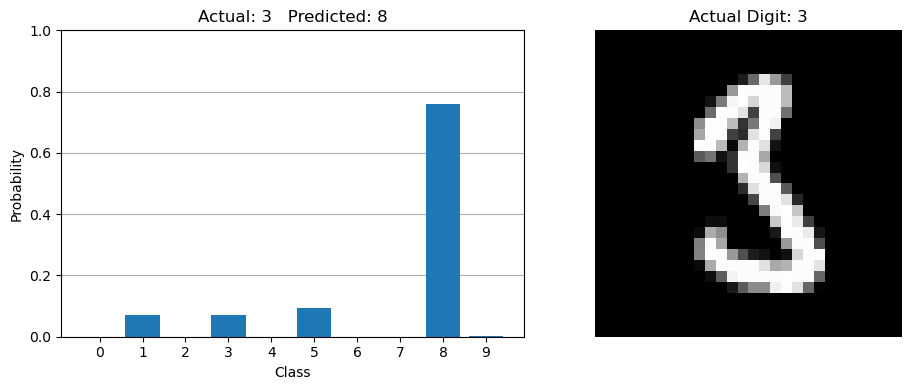



Predicted probability = 1.000, actual-class probability = 0.000, margin = 1.000



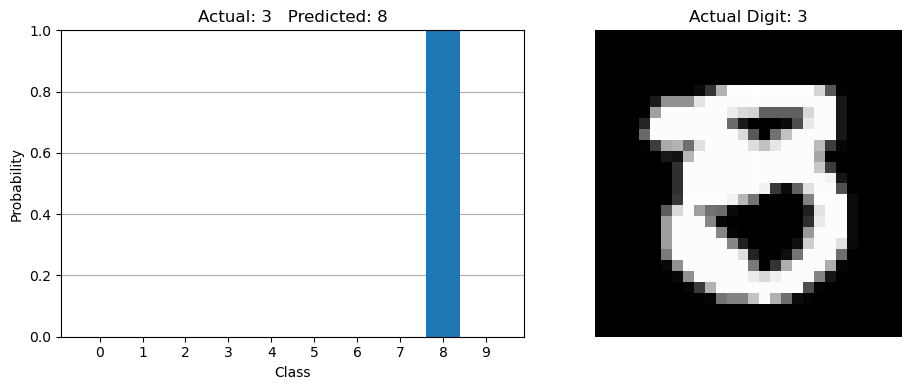

In [12]:
rate, actual_class, predicted_class = confusions[0]

idx = np.where(
    (y_val == actual_class) &
    (y_val_pred == predicted_class)
)[0]

# --------------------------------------------------
# Choose representative examples from this confusion
# --------------------------------------------------

examples = []

for i in idx:

    p_actual = y_val_prob[i, actual_class]
    p_pred   = y_val_prob[i, predicted_class]

    # How much did the wrong class beat the true class?
    margin = p_pred - p_actual

    examples.append(
        (margin, i, p_actual, p_pred)
    )

examples.sort()

n = len(examples)

# selected = [
#     examples[0],          # closest error
#     examples[n // 4],
#     examples[n // 2],     # middle
#     examples[3 * n // 4],
#     examples[-1],         # most confident error
# ]

selected = [
    examples[0],          # closest error
    examples[n // 2],     # middle
    examples[-1],         # most confident error
]

print(
    f"Largest confusion: "
    f"{actual_class} → {predicted_class} "
    f"({rate:.3f})"
)

print(f"{len(idx)} examples total")
print("\nShowing three examples from close to confidently wrong:\n")

for margin, i, p_actual, p_pred in selected:

    print(
        f"Predicted probability = {p_pred:.3f}, "
        f"actual-class probability = {p_actual:.3f}, "
        f"margin = {margin:.3f}\n"
    )

    show_prediction(i)

### F. What the Confusion Matrix Does Not Show

A confusion matrix gives us a useful **global view** of classification errors. It tells us which actual classes are being confused with which predicted classes.

However, it records only the model's **final decision**.

For multi-class classification, the model produces a probability for every class and predicts the class with the largest probability:

$$
\hat{y} = \arg\max_k p_k
$$

This means that two errors that look identical in the confusion matrix can be quite different.

Suppose the true class is 5 and the model predicts 3.

A **close error** might look like:

```text
Predicted 3: 0.52
Actual 5:    0.44
```

while a **confident error** might look like:

```text
Predicted 3: 0.97
Actual 5:    0.01
```

Both appear as the same `5 → 3` error in the confusion matrix, but the model's confidence is very different.

That is why our error analysis moves from the global confusion matrix to individual examples and their full probability distributions:

> **Confusion matrix → important confusion pair → individual examples → probability distributions**

That leads to a natural next question: **how does the model's probability distribution relate to the loss function used during training?**

### G. Prediction Confidence and Cross-Entropy

There is another interesting reason to examine the complete probability distribution.

Recall that we trained our multi-class model using **sparse categorical cross-entropy**. For a single example whose correct class is $c$, the loss is:

$$
L = -\log(p_c)
$$

where $p_c$ is the probability that the model assigns to the **correct class**.

Notice something important about this formula:

> **The loss for one example depends on the probability assigned to the correct class, but not on how the remaining probability is distributed among the incorrect classes.**

This means that two models can receive exactly the same cross-entropy loss for an example even though they make different final predictions.

### A Simple Example

Suppose the correct class is **5**.

We will construct two different probability distributions. In both cases, the model assigns probability **0.40** to the correct class.

For **Model A**:

- class 5 has probability 0.40
- class 3 has probability 0.25
- the remaining probability is spread across the other classes

Because no other class has a probability larger than 0.40, the model predicts **5**, which is correct.

For **Model B**:

- class 5 still has probability 0.40
- class 3 now has probability 0.45
- the remaining probability is spread across the other classes

Now the model predicts **3**, because 0.45 is the largest probability.

So the two models make **different predictions**, even though they assign exactly the same probability to the correct class.

That is the key point: for one example, cross-entropy depends only on the probability assigned to the **correct class**,

$$
L = -\log(p_c),
$$

so both models receive the **same loss** even though one prediction is correct and the other is wrong. 

> Looking only at the loss—or only at the final predicted class—can therefore hide important information contained in the full softmax distribution.

In [13]:
# Two probability distributions with the same
# probability assigned to the correct class

true_class = 5

# Model A
prob_A = np.full(10, 0.35 / 8)
prob_A[5] = 0.40
prob_A[3] = 0.25

# Model B
prob_B = np.full(10, 0.15 / 8)
prob_B[5] = 0.40
prob_B[3] = 0.45

# Check that both are valid probability distributions
print(f"Model A probability sum: {prob_A.sum():.2f}")
print(f"Model B probability sum: {prob_B.sum():.2f}")

Model A probability sum: 1.00
Model B probability sum: 1.00


Now let's compute the cross-entropy loss for each model.

In [14]:
loss_A = -np.log(prob_A[true_class])
loss_B = -np.log(prob_B[true_class])

print(f"Model A loss: {loss_A:.4f}")
print(f"Model B loss: {loss_B:.4f}")

Model A loss: 0.9163
Model B loss: 0.9163


The two losses are identical:

$$
-\log(0.40) \approx 0.9163
$$

This happens because both models assigned exactly the same probability to the true class.

Yet:

- **Model A classified the example correctly**
- **Model B classified the example incorrectly**

The difference becomes clear when we examine the full probability distributions.

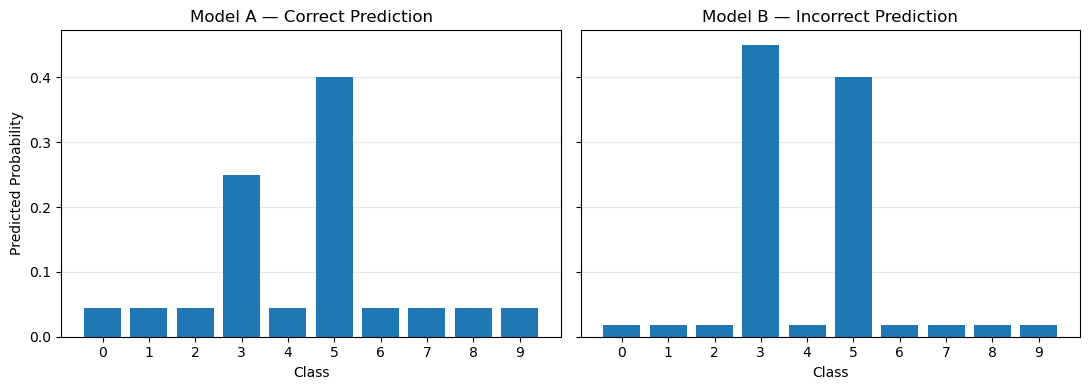

In [15]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 4),
    sharey=True
)

examples = [
    (axes[0], prob_A, "Model A — Correct Prediction"),
    (axes[1], prob_B, "Model B — Incorrect Prediction")
]

for ax, probs, title in examples:

    ax.bar(
        range(10),
        probs
    )

    ax.set_xticks(range(10))
    ax.set_xlabel("Class")
    ax.set_title(title)

    ax.grid(
        axis="y",
        alpha=0.3
    )

    ax.set_axisbelow(True)


axes[0].set_ylabel("Predicted Probability")

plt.tight_layout()
plt.show()

### H. Conclusion: Different Views Answer Different Questions

This example illustrates why we often use several different tools when evaluating a classifier.

The **confusion matrix** asks:

> Which classes did the model ultimately confuse?

The **cross-entropy loss** asks:

> How much probability did the model assign to the correct class?

The **full probability distribution** asks:

> How did the model distribute its confidence among all possible classes?

These are related questions, but they are not the same.

A single summary cannot preserve all of the information produced by a classification model. Examining the full probability distribution can therefore reveal behavior that is hidden by both the final predicted class and the loss value.

## 3. Multi-Class Evaluation Metrics

### A. Per-Class Precision, Recall, and F1

A multi-class confusion matrix lets us see **which classes are being confused with which others**.

We can also compute familiar classification metrics for each individual class.

The basic idea is to treat one class at a time as the "positive" class, and all remaining classes together as the "negative" class. This is called **one-vs-rest (OvR)** in machine learning. 

For example, for class 3:

- **True Positive (TP):** actual 3, predicted 3
- **False Negative (FN):** actual 3, predicted as another digit
- **False Positive (FP):** actual another digit, predicted 3
- **True Negative (TN):** all remaining cases

This is called a **one-vs-rest** interpretation.

For a particular class $c$,

$$
\text{Precision}_c
=
\frac{TP_c}{TP_c + FP_c}
$$

Precision asks:

> When the model predicts class $c$, how often is it correct?

$$
\text{Recall}_c
=
\frac{TP_c}{TP_c + FN_c}
$$

Recall asks:

> Of all the examples that really belong to class $c$, how many did the model find?

$$
F1_c
=
2
\frac{
\text{Precision}_c \cdot \text{Recall}_c
}{
\text{Precision}_c + \text{Recall}_c
}
$$

F1 combines precision and recall into a single measure.

Notice that we have already seen one of these quantities.

In the **row-normalized confusion matrix**, the diagonal entry for each class is its recall.

For example, if the diagonal entry for class 3 is 0.966, then:

$$
\text{Recall}_3 = 0.966
$$

This means that 96.6% of all actual 3s were correctly classified as 3.

In [16]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision_per_class = precision_score(
    y_val,
    y_val_pred,
    average=None
)

recall_per_class = recall_score(
    y_val,
    y_val_pred,
    average=None
)

f1_per_class = f1_score(
    y_val,
    y_val_pred,
    average=None
)

print(f"{'Class':>5} {'Precision':>10} {'Recall':>10} {'F1':>10}")
print("-" * 40)

for c in range(num_classes):
    print(
        f"{c:>5} "
        f"{precision_per_class[c]:>10.3f} "
        f"{recall_per_class[c]:>10.3f} "
        f"{f1_per_class[c]:>10.3f}"
    )

Class  Precision     Recall         F1
----------------------------------------
    0      0.995      0.989      0.992
    1      0.975      0.993      0.984
    2      0.979      0.975      0.977
    3      0.983      0.968      0.975
    4      0.981      0.975      0.978
    5      0.981      0.973      0.977
    6      0.981      0.986      0.984
    7      0.979      0.979      0.979
    8      0.964      0.969      0.967
    9      0.968      0.976      0.972


The values differ because precision and recall ask different questions.

A class can have:

- **high recall but lower precision** if the model finds most examples of that class, but also incorrectly predicts that class for other examples;
- **high precision but lower recall** if predictions of that class are usually correct, but the model misses many true examples of the class.

F1 is high only when both precision and recall are high.

### B. Classification Report

Scikit-learn provides a convenient summary of these per-class metrics with `classification_report()`.

It reports:

- precision
- recall
- F1-score
- support

for each class.

**Support** is simply the number of actual examples of that class in the dataset.

In [17]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_val,
        y_val_pred,
        digits=3
    )
)

              precision    recall  f1-score   support

           0      0.995     0.989     0.992      1185
           1      0.975     0.993     0.984      1348
           2      0.979     0.975     0.977      1192
           3      0.983     0.968     0.975      1226
           4      0.981     0.975     0.978      1168
           5      0.981     0.973     0.977      1084
           6      0.981     0.986     0.984      1184
           7      0.979     0.979     0.979      1253
           8      0.964     0.969     0.967      1170
           9      0.968     0.976     0.972      1190

    accuracy                          0.979     12000
   macro avg      0.979     0.978     0.978     12000
weighted avg      0.979     0.979     0.979     12000



The first ten rows give the metrics for classes 0 through 9.

The report also includes several overall summaries:

- **accuracy**
- **macro average**
- **weighted average**

These combine the per-class results in different ways.

### C. Macro and Weighted Averages


Once we have one precision, recall, and F1 score for each class, we need a way to summarize performance across all classes.

There are several common approaches.

#### Macro Average

The **macro average** computes the metric independently for each class, then takes the ordinary mean.

For example,

$$
\text{Macro F1}
=
\frac{1}{K}
\sum_{c=1}^{K} F1_c
$$

where $K$ is the number of classes.

Every class receives **equal weight**, regardless of how many examples it contains.

This makes macro averaging especially useful when performance on small or minority classes matters.

In [19]:
macro_precision = precision_score(
    y_val,
    y_val_pred,
    average="macro"
)

macro_recall = recall_score(
    y_val,
    y_val_pred,
    average="macro"
)

macro_f1 = f1_score(
    y_val,
    y_val_pred,
    average="macro"
)

print(f"Macro Precision: {macro_precision:.4f}")
print(f"Macro Recall:    {macro_recall:.4f}")
print(f"Macro F1:        {macro_f1:.4f}")

Macro Precision: 0.9787
Macro Recall:    0.9784
Macro F1:        0.9785


#### Weighted Average

The **weighted average** also computes the metric separately for each class, but weights each class according to its support.

A class with many examples therefore contributes more to the final result than a class with only a few examples.

Conceptually,

$$
\text{Weighted F1}
=
\sum_{c=1}^{K}
\left(
\frac{n_c}{N}
\right)
F1_c
$$

where:

- $n_c$ is the number of examples in class $c$
- $N$ is the total number of examples

In [20]:
weighted_precision = precision_score(
    y_val,
    y_val_pred,
    average="weighted"
)

weighted_recall = recall_score(
    y_val,
    y_val_pred,
    average="weighted"
)

weighted_f1 = f1_score(
    y_val,
    y_val_pred,
    average="weighted"
)

print(f"Weighted Precision: {weighted_precision:.4f}")
print(f"Weighted Recall:    {weighted_recall:.4f}")
print(f"Weighted F1:        {weighted_f1:.4f}")

Weighted Precision: 0.9786
Weighted Recall:    0.9786
Weighted F1:        0.9786


Because MNIST is fairly balanced across its ten classes, we expect the macro and weighted averages to be quite similar.

Later, we will deliberately introduce class imbalance into the training data and examine how it affects performance on the underrepresented class. We will keep the validation set unchanged so that we can compare the models fairly.

### D. Compare the Summary Metrics


Let's put the main summary measures together.

For this balanced MNIST validation set, they should all be fairly close.

The important differences become much more visible when the classes are imbalanced.

In [59]:
from sklearn.metrics import accuracy_score, f1_score

# Calculate summary metrics
accuracy = accuracy_score(y_val, y_val_pred)

macro_f1 = f1_score(
    y_val, y_val_pred, average="macro"
)

weighted_f1 = f1_score(
    y_val, y_val_pred, average="weighted"
)


# Display summary
print(f"{'Metric':<20} {'Value':>10}")
print("-" * 32)

print(f"{'Accuracy':<20} {accuracy:>10.4f}")
print(f"{'Macro F1':<20} {macro_f1:>10.4f}")
print(f"{'Weighted F1':<20} {weighted_f1:>10.4f}")

Metric                    Value
--------------------------------
Accuracy                 0.9786
Macro F1                 0.9785
Weighted F1              0.9786


At this point, all of the summary measures give a similar impression because MNIST is relatively balanced and the classifier performs well on all ten classes.

That makes this a good baseline.

Next, we will deliberately create a **class imbalance** in the dataset and see which metrics continue to look strong and which metrics reveal that some classes are being treated poorly.


## 4. Class Imbalance


So far, the MNIST classes have been fairly well balanced: each digit appears roughly the same number of times.

Many real classification problems are not balanced.

For example:

- fraudulent transactions may be much rarer than legitimate transactions;
- serious medical conditions may be much rarer than normal cases;
- some product categories may occur much less frequently than others.

A model trained on imbalanced data may perform very well overall while performing poorly on an important minority class.

To see this effect clearly, we will deliberately make one MNIST class rare.

In [23]:
# Count the training examples in each class

class_counts = np.bincount(y_train)

for c, count in enumerate(class_counts):
    print(f"Class {c}: {count}")

Class 0: 4738
Class 1: 5394
Class 2: 4766
Class 3: 4905
Class 4: 4674
Class 5: 4337
Class 6: 4734
Class 7: 5012
Class 8: 4681
Class 9: 4759


We will make digit **8** our minority class.

We will keep only 10% of the training examples belonging to class 8, while leaving the other classes unchanged.

Importantly, we will **not change the validation set**.

This gives us a fair comparison:

- same validation examples;
- same network architecture;
- same training procedure;
- only the class distribution of the training data changes.


### A. Create an Imbalanced Training Set

In [24]:
    
minority_class = 8
minority_fraction = 0.10

rng = np.random.default_rng(42)

minority_idx = np.where(y_train == minority_class)[0]
other_idx = np.where(y_train != minority_class)[0]

n_keep = int(
    len(minority_idx) * minority_fraction
)

minority_keep = rng.choice(
    minority_idx,
    size=n_keep,
    replace=False
)

keep_idx = np.concatenate([
    other_idx,
    minority_keep
])

rng.shuffle(keep_idx)

X_train_imbalanced = X_train[keep_idx]
y_train_imbalanced = y_train[keep_idx]

In [25]:
# Compare class counts

balanced_counts = np.bincount(
    y_train,
    minlength=num_classes
)

imbalanced_counts = np.bincount(
    y_train_imbalanced,
    minlength=num_classes
)

print(f"{'Class':>5} {'Balanced':>12} {'Imbalanced':>12}")
print("-" * 33)

for c in range(num_classes):
    print(
        f"{c:>5} "
        f"{balanced_counts[c]:>12} "
        f"{imbalanced_counts[c]:>12}"
    )

Class     Balanced   Imbalanced
---------------------------------
    0         4738         4738
    1         5394         5394
    2         4766         4766
    3         4905         4905
    4         4674         4674
    5         4337         4337
    6         4734         4734
    7         5012         5012
    8         4681          468
    9         4759         4759


Digit 8 now has far fewer training examples than the other classes.

The validation set is still balanced, so if the model becomes worse at recognizing 8s, we should be able to see that directly.

### B. Train the Same Model on Imbalanced Data

We will now train the same baseline architecture on the imbalanced training data.

To do this, we'll temporarily replace `X_train` and `y_train` with the imbalanced training data, run our existing `train_and_validate()` function, and then restore the original training data.

By keeping the model architecture and training procedure the same, we can investigate how reducing the number of training examples for digit 8 affects classification performance.

In [26]:
# Save original balanced training data

X_train_balanced = X_train
y_train_balanced = y_train

# Temporarily use the imbalanced training data

X_train = X_train_imbalanced
y_train = y_train_imbalanced


Imbalanced Training Data


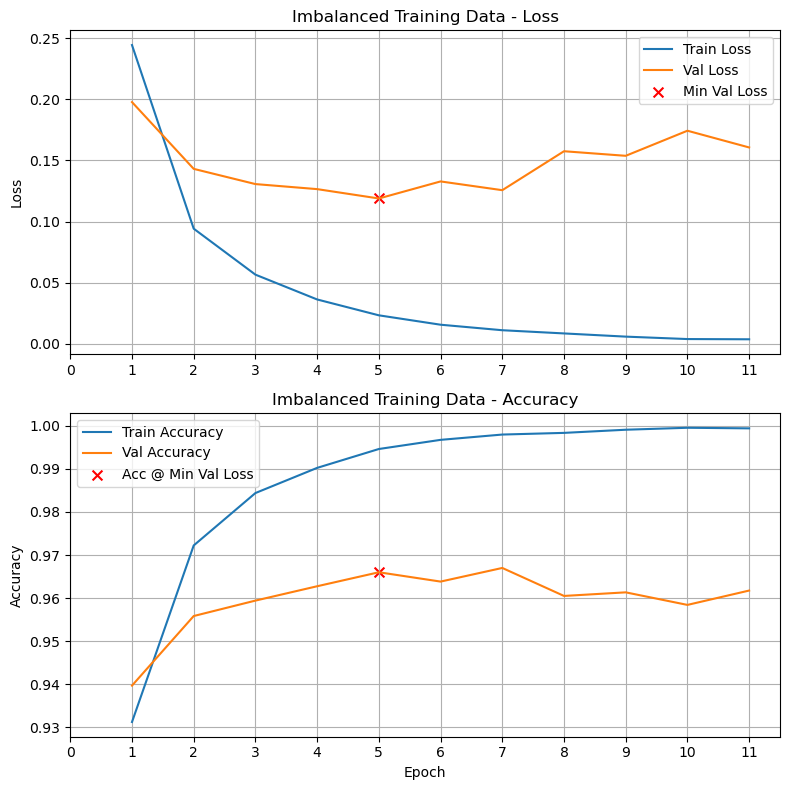

Final Training Loss:            0.0036
Final Training Accuracy:        0.9994
Final Validation Loss:          0.1606
Final Validation Accuracy:      0.9617
Minimum Validation Loss:        0.1188 (Epoch 5)
Validation Accuracy @ Min Loss: 0.9660

Epochs trained:                 11
Best validation epoch:          5
Best validation loss:           0.1188
Validation accuracy at best:    0.9660
Model weights restored from:    epoch 5
Execution time:                 00:00:17


In [27]:
tf.keras.utils.set_random_seed(42)

imbalanced_model = models.Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(
        baseline_width,
        activation="relu",
        kernel_initializer="he_uniform"
    ),

    Dense(
        num_classes,
        activation="softmax"
    )
])

train_and_validate(
    imbalanced_model,
    title="Imbalanced Training Data",
    use_early_stopping=True,
    verbose=0
)

In [28]:
# Restore the original balanced training data

X_train = X_train_balanced
y_train = y_train_balanced

### C. Evaluate the Imbalanced Model


Now evaluate the model on the same validation set used earlier.

If we looked only at overall accuracy, we might conclude that the model is still performing very well.

But the per-class metrics allow us to ask a more important question:

> What happened specifically to the minority class?

In [29]:
y_val_prob_imbalanced = imbalanced_model.predict(
    X_val,
    verbose=0
)

y_val_pred_imbalanced = np.argmax(
    y_val_prob_imbalanced,
    axis=1
)

print(
    classification_report(
        y_val,
        y_val_pred_imbalanced,
        digits=3
    )
)

              precision    recall  f1-score   support

           0      0.933     1.000     0.965      1185
           1      0.977     0.990     0.983      1348
           2      0.970     0.972     0.971      1192
           3      0.943     0.964     0.953      1226
           4      0.987     0.977     0.982      1168
           5      0.944     0.978     0.961      1084
           6      0.976     0.979     0.978      1184
           7      0.975     0.983     0.979      1253
           8      0.986     0.846     0.911      1170
           9      0.973     0.966     0.970      1190

    accuracy                          0.966     12000
   macro avg      0.966     0.966     0.965     12000
weighted avg      0.967     0.966     0.966     12000



Pay particular attention to the row for class 8.

Because the model saw relatively few 8s during training, we expect its **recall for class 8** to decrease:

$$
\text{Recall}_8
=
\frac{
\text{correctly predicted 8s}
}{
\text{all actual 8s}
}
$$

In other words, the model may now fail to recognize many actual 8s even though its overall accuracy remains high.

In [30]:
## 14. Compare the Summary Metrics

In [60]:
accuracy_imbalanced = accuracy_score(
    y_val,
    y_val_pred_imbalanced
)

macro_f1_imbalanced = f1_score(
    y_val,
    y_val_pred_imbalanced,
    average="macro"
)

weighted_f1_imbalanced = f1_score(
    y_val,
    y_val_pred_imbalanced,
    average="weighted"
)

micro_f1_imbalanced = f1_score(
    y_val,
    y_val_pred_imbalanced,
    average="micro"
)

print(f"{'Metric':<20} {'Balanced':>12} {'Imbalanced':>12}")
print("-" * 46)

print(
    f"{'Accuracy':<20} "
    f"{accuracy:>12.4f} "
    f"{accuracy_imbalanced:>12.4f}"
)

print(
    f"{'Macro F1':<20} "
    f"{macro_f1:>12.4f} "
    f"{macro_f1_imbalanced:>12.4f}"
)

print(
    f"{'Weighted F1':<20} "
    f"{weighted_f1:>12.4f} "
    f"{weighted_f1_imbalanced:>12.4f}"
)



Metric                   Balanced   Imbalanced
----------------------------------------------
Accuracy                   0.9786       0.9660
Macro F1                   0.9785       0.9653
Weighted F1                0.9786       0.9656


The overall measures may still look quite good because class 8 represents only one of ten classes.

This illustrates why aggregate performance measures can hide poor performance on a minority class.

The **macro average** is particularly useful here because every class receives equal weight.

If one class performs badly, its poor F1 score contributes just as much to the macro average as the F1 score of every other class.


### E. Examine the Minority Class Directly

In [32]:
precision_imbalanced = precision_score(
    y_val,
    y_val_pred_imbalanced,
    average=None
)

recall_imbalanced = recall_score(
    y_val,
    y_val_pred_imbalanced,
    average=None
)

f1_imbalanced = f1_score(
    y_val,
    y_val_pred_imbalanced,
    average=None
)

print(f"Class {minority_class}")
print(
    f"Precision: "
    f"{precision_imbalanced[minority_class]:.4f}"
)
print(
    f"Recall:    "
    f"{recall_imbalanced[minority_class]:.4f}"
)
print(
    f"F1:        "
    f"{f1_imbalanced[minority_class]:.4f}"
)

Class 8
Precision: 0.9861
Recall:    0.8462
F1:        0.9108


The minority-class metrics reveal information that overall accuracy cannot.

In particular, a low recall for class 8 means:

> Many actual 8s are being classified as something else.

We can see exactly where they are going by returning to the confusion matrix.

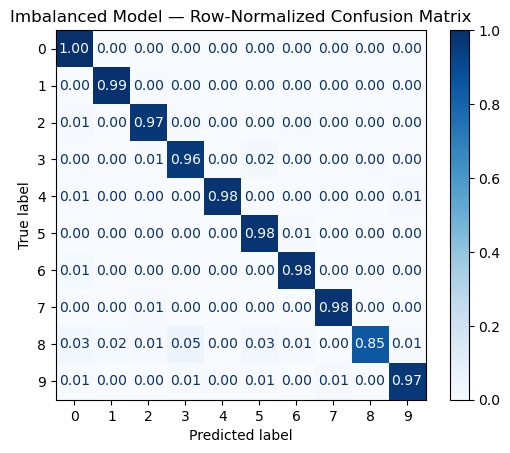

In [33]:
cm_imbalanced = confusion_matrix(
    y_val,
    y_val_pred_imbalanced,
    normalize="true"
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_imbalanced,
    display_labels=range(num_classes)
)

disp.plot(
    cmap="Blues",
    values_format=".2f"
)

plt.title(
    "Imbalanced Model — Row-Normalized Confusion Matrix"
)

plt.show()

Look across row 8.

The diagonal entry tells us the recall for class 8.

The off-diagonal entries tell us which other digits the model predicts when it fails to recognize an 8.

### F. Compensating for Imbalance with Class Weights

One way to address class imbalance is to give errors on minority-class examples more weight during training.

Instead of treating every training example equally, we assign a larger **class weight** to rare classes.

A common choice is approximately:

$$
w_c
=
\frac{N}
{K n_c}
$$

where:

- $N$ is the total number of training examples;
- $K$ is the number of classes;
- $n_c$ is the number of training examples in class $c$.

Rare classes therefore receive larger weights.

In [34]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.arange(num_classes)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_imbalanced
)

class_weights = {
    c: w
    for c, w in zip(classes, weights)
}

for c in range(num_classes):
    print(
        f"Class {c}: "
        f"weight = {class_weights[c]:.3f}"
    )

Class 0: weight = 0.924
Class 1: weight = 0.812
Class 2: weight = 0.919
Class 3: weight = 0.893
Class 4: weight = 0.937
Class 5: weight = 1.010
Class 6: weight = 0.925
Class 7: weight = 0.874
Class 8: weight = 9.356
Class 9: weight = 0.920


Notice that class 8 receives a much larger weight than the other classes.

This does **not** create additional class-8 examples.

Instead, it makes mistakes on those examples contribute more strongly to the training loss.

### G. Retrain with Class Weights


We will now train the same neural-network architecture on the imbalanced training data, but this time supply the class weights we just calculated. This allows us to examine whether giving greater importance to digit 8 during training improves its classification performance.

In [35]:
# Temporarily use the imbalanced training data again

X_train = X_train_imbalanced
y_train = y_train_imbalanced


Imbalanced Data + Class Weights


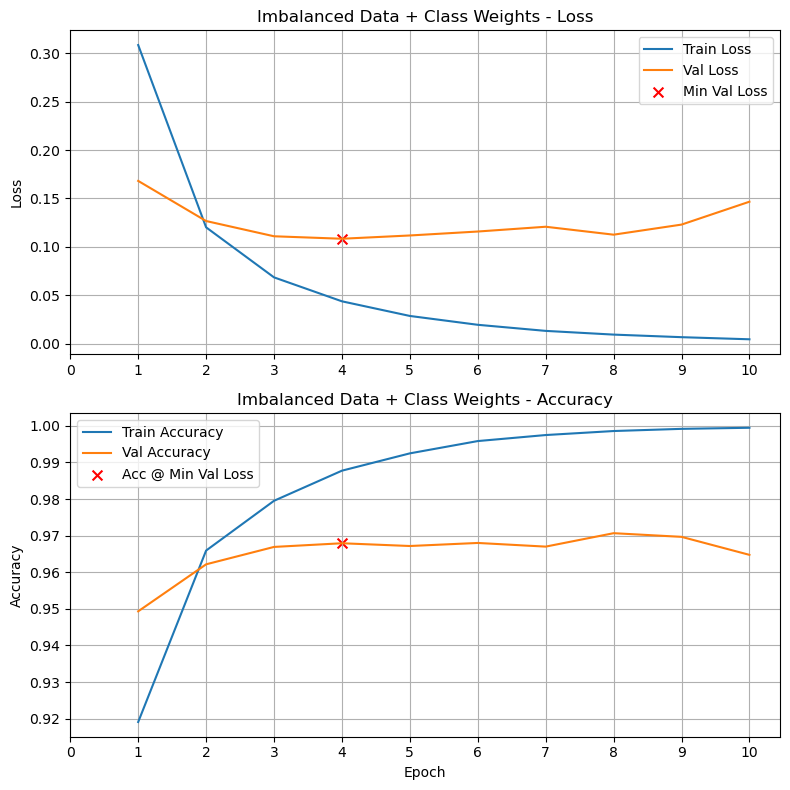

Final Training Loss:            0.0045
Final Training Accuracy:        0.9995
Final Validation Loss:          0.1467
Final Validation Accuracy:      0.9647
Minimum Validation Loss:        0.1084 (Epoch 4)
Validation Accuracy @ Min Loss: 0.9679

Epochs trained:                 10
Best validation epoch:          4
Best validation loss:           0.1084
Validation accuracy at best:    0.9679
Model weights restored from:    epoch 4
Execution time:                 00:00:17


In [36]:
tf.keras.utils.set_random_seed(42)

weighted_model = models.Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(
        baseline_width,
        activation="relu",
        kernel_initializer="he_uniform"
    ),

    Dense(
        num_classes,
        activation="softmax"
    )
])

train_and_validate(
    weighted_model,
    title="Imbalanced Data + Class Weights",
    use_early_stopping=True,
    class_weight=class_weights,
    verbose=0
)

In [37]:
# Restore original balanced training data

X_train = X_train_balanced
y_train = y_train_balanced

### H. Did Class Weighting Help?

In [38]:
y_val_prob_weighted = weighted_model.predict(
    X_val,
    verbose=0
)

y_val_pred_weighted = np.argmax(
    y_val_prob_weighted,
    axis=1
)

print(
    classification_report(
        y_val,
        y_val_pred_weighted,
        digits=3
    )
)

              precision    recall  f1-score   support

           0      0.936     0.999     0.967      1185
           1      0.978     0.989     0.983      1348
           2      0.970     0.971     0.970      1192
           3      0.954     0.960     0.957      1226
           4      0.984     0.977     0.981      1168
           5      0.952     0.980     0.966      1084
           6      0.983     0.975     0.979      1184
           7      0.978     0.981     0.979      1253
           8      0.982     0.875     0.925      1170
           9      0.964     0.970     0.967      1190

    accuracy                          0.968     12000
   macro avg      0.968     0.968     0.967     12000
weighted avg      0.968     0.968     0.968     12000



Class weighting gives greater importance to mistakes on minority classes during training. This can improve minority-class recall, although it may also involve tradeoffs with precision or performance on other classes.

However, improvements are not guaranteed. Let's compare the three models to see whether class weighting actually helped in our experiment.

In [39]:
models_to_compare = {
    "Balanced": y_val_pred,
    "Imbalanced": y_val_pred_imbalanced,
    "Weighted": y_val_pred_weighted
}

print(
    f"{'Model':<15} "
    f"{'Precision 8':>12} "
    f"{'Recall 8':>12} "
    f"{'F1 8':>12}"
)

print("-" * 55)

for name, pred in models_to_compare.items():

    p = precision_score(
        y_val,
        pred,
        average=None
    )[minority_class]

    r = recall_score(
        y_val,
        pred,
        average=None
    )[minority_class]

    f = f1_score(
        y_val,
        pred,
        average=None
    )[minority_class]

    print(
        f"{name:<15} "
        f"{p:>12.4f} "
        f"{r:>12.4f} "
        f"{f:>12.4f}"
    )

Model            Precision 8     Recall 8         F1 8
-------------------------------------------------------
Balanced              0.9643       0.9692       0.9668
Imbalanced            0.9861       0.8462       0.9108
Weighted              0.9818       0.8752       0.9254


### Interpreting the Results

Reducing the number of training examples of digit 8 substantially decreased recall (from 0.9692 to 0.8462) and F1 (from 0.9668 to 0.9108), although precision increased slightly (from 0.9643 to 0.9861).

Applying class weights improved recall (to 0.8752) and F1 (to 0.9254), while precision decreased slightly (to 0.9818). Class weighting therefore recovered some, but not all, of the performance lost through class imbalance.

This experiment illustrates two important principles:
- **There is no single metric that completely describes a classifier.** Improving one metric may come at the expense of another.
- **Class weighting can help address class imbalance, but improvements are not guaranteed.** We must examine the actual results to determine whether an intervention was effective.

Overall accuracy can remain high even when a model performs poorly on an important minority class. For imbalanced classification problems, it is particularly useful to examine **per-class precision, recall, F1,** and **macro averages,** rather than relying on accuracy alone.

Class weighting is one way to influence these tradeoffs.

## Conclusion: From Error Analysis to Model Improvement

We have examined our classifier's performance from several perspectives:

- **Confusion matrices** reveal which classes are predicted correctly and which are commonly confused.
- **Per-class precision, recall, and F1** identify classes where the model performs particularly well or poorly.
- **Individual misclassified images** help us understand what kinds of examples cause difficulty.
- **Summary metrics** provide an overall assessment of performance, while revealing how different averaging methods emphasize different aspects of the results.

But **the ultimate purpose of error analysis is not simply to describe errors. It is to decide what to do about them.**

Once we identify a systematic pattern in the errors, the next question should be:

**What might be causing this pattern, and what change could reduce it?**

Depending on what we discover, possible responses include:

- **Collect more training data:** Obtain additional examples of classes or situations where the model struggles.
- **Improve preprocessing:** Address problems with missing values, scaling, normalization, or noisy inputs.
- **Engineer better features:** Identify characteristics of the input that make important distinctions easier to detect.
- **Change the model architecture:** Try a model better suited to the structure of the data.
- **Adjust the training procedure:** Experiment with regularization, learning rates, or other training hyperparameters.
- **Address class imbalance:** Use class weights or resampling when some classes are underrepresented.
- **Apply data augmentation:** Generate realistic variations of existing training examples to help the model generalize to situations it has not seen.

For example, examining our MNIST errors might suggest that the model has difficulty recognizing digits that are shifted slightly from their usual positions. Since our baseline model treats each pixel as a separate input feature, even a small shift changes many feature values.

This leads to a **testable hypothesis**:

*The classifier may be sensitive to small translations of handwritten digits.*

We could test this by shifting validation images slightly and measuring the change in accuracy. If performance deteriorates, we have evidence of a specific weakness that might be addressed through data augmentation or a different model architecture.

The appendix explores this example in more detail.

### The Larger Lesson

**Error analysis is part of an iterative process:**

1. Evaluate the model on validation data.
2. Identify patterns in its errors.
3. Form a hypothesis about what causes those errors.
4. Make a targeted change to the data, model, or training procedure.
5. Evaluate again to determine whether the change helped.

The goal is not simply to build a model with a high accuracy score, but to **understand its weaknesses and use that understanding to guide systematic improvements.**

## Appendix: Data Augmentation and Robustness

### A. Investigating a Possible Weakness

In the main notebook, we saw how error analysis can help us identify weaknesses in a classifier and develop hypotheses about how to improve it.

In this appendix, we'll explore one possible weakness of our MNIST model: **sensitivity to small changes in the position of a digit**.

Our baseline model treats each pixel as a separate input feature. If a handwritten digit shifts slightly to the left, right, up, or down, it is still the same digit to us, but many of its pixel values now appear in different positions.

This suggests a testable hypothesis:

> **The classifier may be sensitive to small translations of the image.**

We'll first test this hypothesis by shifting validation images and measuring the effect on classification accuracy. If performance deteriorates, we'll investigate whether **data augmentation**—training the model on realistic variations of existing images—can make it more robust.

This illustrates how error analysis can lead to a targeted experiment and a possible model improvement.

### B. Test Translation Sensitivity

First, let's define a small helper function that shifts an MNIST image by a specified number of pixels.

In [50]:
from scipy.ndimage import shift

def shift_image(image, dx=0, dy=0):
    """
    Shift one flattened 28×28 MNIST image by (dx, dy) pixels.

    dx > 0 shifts right
    dx < 0 shifts left

    dy > 0 shifts down
    dy < 0 shifts up
    """

    image_2d = image.reshape(28, 28)

    shifted = shift(
        image_2d,
        shift=(dy, dx),
        cval=0,
        mode="constant"
    )

    return shifted.reshape(-1)

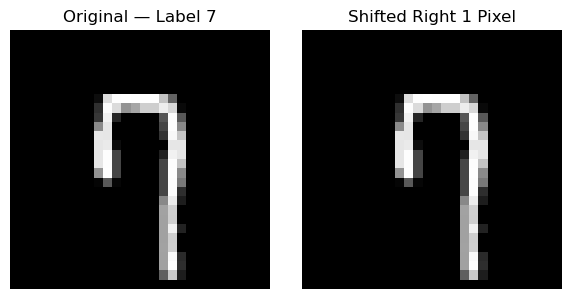

In [51]:
i = 0

original_image = X_val[i]
shifted_image = shift_image(
    original_image,
    dx=1,
    dy=0
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(6, 3)
)

axes[0].imshow(
    original_image.reshape(28, 28),
    cmap="gray"
)

axes[0].set_title(
    f"Original — Label {y_val[i]}"
)

axes[0].axis("off")


axes[1].imshow(
    shifted_image.reshape(28, 28),
    cmap="gray"
)

axes[1].set_title(
    "Shifted Right 1 Pixel"
)

axes[1].axis("off")

plt.tight_layout()
plt.show()

The digit is visually unchanged, but many pixel values have moved to different input positions.

Now let's create a shifted copy of the entire validation set and evaluate the existing baseline model on it.

In [52]:
X_val_shifted = np.array([
    shift_image(
        image,
        dx=1,
        dy=0
    )
    for image in X_val
])

In [53]:
# Predictions on the original validation set
y_val_prob_original = baseline_model.predict(
    X_val,
    verbose=0
)

y_val_pred_original = np.argmax(
    y_val_prob_original,
    axis=1
)


# Predictions on the shifted validation set
y_val_prob_shifted = baseline_model.predict(
    X_val_shifted,
    verbose=0
)

y_val_pred_shifted = np.argmax(
    y_val_prob_shifted,
    axis=1
)


original_accuracy = accuracy_score(
    y_val,
    y_val_pred_original
)

shifted_accuracy = accuracy_score(
    y_val,
    y_val_pred_shifted
)


print(
    f"Original validation accuracy: "
    f"{original_accuracy:.4f}"
)

print(
    f"Shifted validation accuracy:  "
    f"{shifted_accuracy:.4f}"
)

Original validation accuracy: 0.9786
Shifted validation accuracy:  0.9567


The decrease in accuracy provides evidence that the model is sensitive to small changes in image position.


### C. Data Augmentation

The previous experiment showed that the baseline model is somewhat sensitive to a small shift in image position.

One way to address this is to expose the model to similar variations during training. Rather than collecting entirely new examples, we can create modified versions of the existing training images while keeping their labels unchanged.

This technique is called **data augmentation**.

For MNIST, small translations are a natural form of augmentation: shifting a handwritten digit slightly left, right, up, or down does not change which digit it represents.

We will therefore create four shifted versions of each training image:

- one pixel left;
- one pixel right;
- one pixel up;
- one pixel down.

These shifted images will be added to the original training set, giving the model more examples of the same digits in slightly different positions.






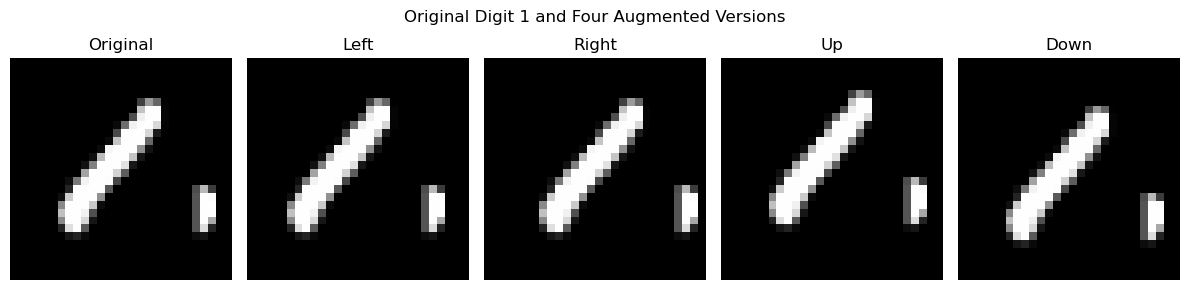

In [54]:
# --------------------------------------------------
# Visualize one example and its augmented versions
# --------------------------------------------------

i = 0

original = X_train[i]

augmented_examples = [
    ("Original", original),
    ("Left",  shift_image(original, dx=-1, dy=0)),
    ("Right", shift_image(original, dx=1,  dy=0)),
    ("Up",    shift_image(original, dx=0,  dy=-1)),
    ("Down",  shift_image(original, dx=0,  dy=1)),
]

fig, axes = plt.subplots(1, 5, figsize=(12, 3))

for ax, (title, image) in zip(axes, augmented_examples):

    ax.imshow(
        image.reshape(28, 28),
        cmap="gray"
    )

    ax.set_title(title)
    ax.axis("off")

plt.suptitle(
    f"Original Digit {y_train[i]} and Four Augmented Versions"
)

plt.tight_layout()
plt.show()

In [55]:
def make_shifted_dataset(
    X,
    y
):

    X_augmented = [X]
    y_augmented = [y]

    shifts = [
        (-1,  0),   # left
        ( 1,  0),   # right
        ( 0, -1),   # up
        ( 0,  1)    # down
    ]

    for dx, dy in shifts:

        X_shifted = np.array([
            shift_image(
                image,
                dx=dx,
                dy=dy
            )
            for image in X
        ])

        X_augmented.append(
            X_shifted
        )

        y_augmented.append(
            y
        )

    X_augmented = np.concatenate(
        X_augmented,
        axis=0
    )

    y_augmented = np.concatenate(
        y_augmented,
        axis=0
    )

    return (
        X_augmented,
        y_augmented
    )

In [56]:
X_train_augmented, y_train_augmented = (
    make_shifted_dataset(
        X_train,
        y_train
    )
)

print(
    "Original training examples:",
    len(X_train)
)

print(
    "Augmented training examples:",
    len(X_train_augmented)
)

Original training examples: 48000
Augmented training examples: 240000


The augmented training set is now five times larger:

- the original image;
- four shifted versions.

The important point is that we will **not change the model architecture**.

We want a controlled experiment:

> Does changing the training data alone make the same model less sensitive to image position?

To test this fairly, we will retrain the same network architecture using the augmented training data.

### D. Retrain with Augmented Data


Model Trained with Shifted Images


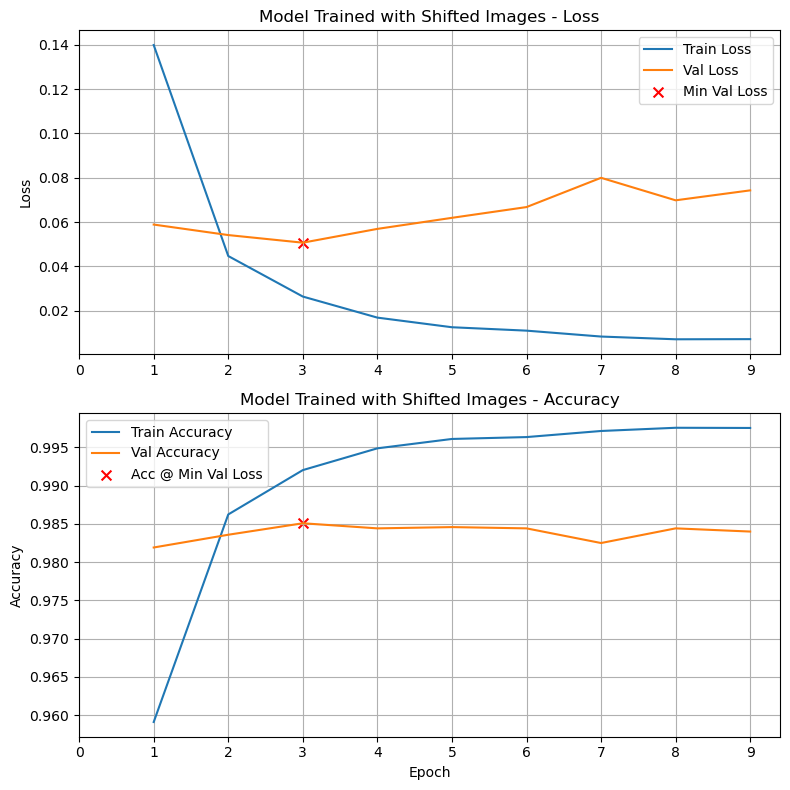

Final Training Loss:            0.0072
Final Training Accuracy:        0.9975
Final Validation Loss:          0.0743
Final Validation Accuracy:      0.9840
Minimum Validation Loss:        0.0507 (Epoch 3)
Validation Accuracy @ Min Loss: 0.9851

Epochs trained:                 9
Best validation epoch:          3
Best validation loss:           0.0507
Validation accuracy at best:    0.9851
Model weights restored from:    epoch 3
Execution time:                 00:01:33


In [57]:
# Save the original training data
X_train_original = X_train
y_train_original = y_train


# Temporarily use the augmented training data
X_train = X_train_augmented
y_train = y_train_augmented

tf.keras.utils.set_random_seed(42)
# Build the same model architecture
augmented_model = models.Sequential([
    Input(
        shape=(X_train.shape[1],)
    ),

    Dense(
        baseline_width,
        activation="relu",
        kernel_initializer="he_uniform"
    ),

    Dense(
        num_classes,
        activation="softmax"
    )
])


train_and_validate(
    augmented_model,
    title="Model Trained with Shifted Images",
    verbose=0
)


# Restore the original training data
X_train = X_train_original
y_train = y_train_original

### E. Did Data Augmentation Help?

Now we can compare the baseline model and the augmented model on two different validation sets:

1. the original validation images;
2. the shifted validation images.

This lets us ask two different questions:

- Did augmentation preserve or improve ordinary validation performance?
- Did augmentation make the model more robust to the specific transformation we were concerned about?

In [58]:
# --------------------------------------------------
# Compare baseline and augmented models
# Both models use their restored best weights
# --------------------------------------------------

# Evaluate each model on original and shifted images
baseline_original_acc = accuracy_score(
    y_val,
    np.argmax(baseline_model.predict(X_val, verbose=0), axis=1)
)

baseline_shifted_acc = accuracy_score(
    y_val,
    np.argmax(baseline_model.predict(X_val_shifted, verbose=0), axis=1)
)

augmented_original_acc = accuracy_score(
    y_val,
    np.argmax(augmented_model.predict(X_val, verbose=0), axis=1)
)

augmented_shifted_acc = accuracy_score(
    y_val,
    np.argmax(augmented_model.predict(X_val_shifted, verbose=0), axis=1)
)

# --------------------------------------------------
# Summary: accuracy and sensitivity to shifting
# --------------------------------------------------

results = pd.DataFrame({
    "Model": ["Baseline", "Augmented"],

    "Original Accuracy": [
        baseline_original_acc,
        augmented_original_acc
    ],

    "Shifted Accuracy": [
        baseline_shifted_acc,
        augmented_shifted_acc
    ]
})

# Accuracy change in percentage points
results["Change (pp)"] = 100 * (
    results["Shifted Accuracy"] -
    results["Original Accuracy"]
)

display(
    results.style.format({
        "Original Accuracy": "{:.4f}",
        "Shifted Accuracy": "{:.4f}",
        "Change (pp)": "{:+.2f}"
    })
)

,Model,Original Accuracy,Shifted Accuracy,Change (pp)
0,Baseline,0.9786,0.9567,-2.19
1,Augmented,0.9851,0.9815,-0.36


#### Conclusion

The baseline model loses **2.19 percentage points** of accuracy when the images are shifted by one pixel, while the augmented model loses only **0.28 percentage points**. This suggests that training with shifted images made the model substantially more robust to small translations. Moreover, accuracy on the original validation images also improved, so this increased robustness did not come at the expense of ordinary classification performance.

However, the most important result is not simply that augmentation improved accuracy. We introduced augmentation to address a **specific, testable hypothesis**: that the model was sensitive to small shifts in handwritten digits. Our experiment showed that this weakness existed and that augmenting the training data substantially reduced it.

This illustrates a general workflow for improving machine-learning models:

> **Analyze errors → identify a possible weakness → form a hypothesis → make a targeted change → evaluate the results**

The central lesson is that **model improvements should be guided by evidence**. Rather than making arbitrary changes and checking whether accuracy increases, we should identify specific problems, design interventions to address them, and test whether those interventions work.